In [1]:
#import argparse
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import glob
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from matplotlib.colors import LogNorm, TwoSlopeNorm


sipm_channels = ([4,5,6,7,8,9] + \
                [10,11,12,13,14,15] + \
                [20,21,22,23,24,25] + \
                [26,27,28,29,30,31] + \
                [36,37,38,39,40,41] + \
                [42,43,44,45,46,47] + \
                [52,53,54,55,56,57] + \
                [58,59,60,61,62,63]) # Active channels

In [ ]:
# Aggregate data for different voltages
def agg_data(file_names, voltages):

    # Check if the values provided for voltage match the file names (in number) # Might add check for correct values
    if len(file_names) != len(voltages):
        raise ValueError("File names and provided voltages do not match in length")
        return

    gains = np.zeros((len(file_names),8,64,3)) # First axis is bias voltages
    for idx, file_name in enumerate(file_names):

        data = np.load(file_name)
        gains[idx,...] = data['data']

    return gains

# Check chi squared value
def check_chisquared(array, sipm_channels):
    """ Provide a numpy array of shape (V,8,64,2) for (n_voltages, n_adc, n_ch, dim2) with in the second dimension (gain, chi squared)"""
    gains = array[...,0]
    chisquared = array[...,1]

    # Loop over active channels and count the fits that are between 0.5 and 1.5 for each channel
    for adc in range(0, gains.shape[1]):

        for ch in range(0, gains.shape[2]):
            if ch not in sipm_channels:
                pass
            else:
                #print(f"ADC {adc}, ch {ch}, {chisquared[:,adc,ch]}")
                
                if sum(0.5 <= x <= 1.5 for x in chisquared[:,adc,ch]) >= 4:
                    print(adc, ch)
                

    return

# Fitting function
def linear_fit(gains, voltages, pdf_filename, plot=False, verbose=False):
    """ WLS fit based on reduced chi squared values obtained from the multiple Gaussian model."""
    sipm_channels = ([4,5,6,7,8,9] + \
                     [10,11,12,13,14,15] + \
                     [20,21,22,23,24,25] + \
                     [26,27,28,29,30,31] + \
                     [36,37,38,39,40,41] + \
                     [42,43,44,45,46,47] + \
                     [52,53,54,55,56,57] + \
                     [58,59,60,61,62,63]) # Active channels
    
    voltages = np.array(voltages)
    fit_res = np.zeros((8,64,2)) # Store the coefficients of the linear fit per adc per channel here
    r_squared = np.zeros((8,64)) # Coefficient of determination
    pvalues = np.zeros((8,64,2)) # Check if coefficients are significantly different from zero
    bdv_value = np.zeros((8,64))
   
    plots_per_fig = 4
    no_fit = 0
    with PdfPages(pdf_filename) as pdf_output:
        for adc in range(0, 8):
        #for adc in range(5,6):

            for ch in range(0,gains.shape[2]):
                print('Current channel', ch)
                if ch not in sipm_channels: 
                    pass # Skip inactive channels

                else: # Fit for each channel separately, because the nr of good fits varies per channel
                    gains_per_chan = gains[:,adc,ch,:] # 2D array with gain+stats for all voltages (voltages, gains/stats)
                    print(gains_per_chan)
                    if np.sum(gains_per_chan) == 0:
                        if verbose:
                            print(f"No values available for ADC {adc} ch {ch}")

                    else:
                        cut_1 = (gains_per_chan[:,0] !=0) # Take out zero gains bc those are failed/bad fits
                        cut_2 = (gains_per_chan[:,1] < 1.5) & (gains_per_chan[:,1] > .5) # We only want to look at fitted gains that had a 'good' chi squared value
                        cut_combi =  cut_1 #* cut_2
                        gains_per_chan_v1 = gains_per_chan[cut_combi] 
                        if (gains_per_chan[~cut_combi].size != 0) and verbose:
                            print(f"We don't take these values into account for ADC {adc} ch {ch} \n", gains_per_chan[~cut_combi], "\n At voltages ", voltages[~cut_combi])

                        voltages_v1 = voltages[cut_combi]

                        cut_3 = gains_per_chan_v1.size > 0  # Skip arrays that are empty after our first cut
                        if cut_3 == 1:

                            # Now check if for increasing voltages, the gain decreases. If that happens, something went wrong and we don't want to use that value in the fit.
                            gains_per_chan_v2 = np.array([gains_per_chan_v1[0]]) # Store the first gain value in a new array
                            voltages_v2 = np.array(voltages_v1[0])

                            for idx_v in range(1,len(voltages_v1)): # Start checking from the second value
                                if gains_per_chan_v1[idx_v,0] < gains_per_chan_v2[-1,0]: # Skip if the gain is lower than the last one that passed the cut
                                    if verbose:
                                        print(f"Probably {voltages_v1[idx_v]} is a bad fit for ADC {adc} ch {ch}")
                                        print(f"Gain for {voltages_v1[idx_v-1]}V: {gains_per_chan_v1[idx_v-1,0]}")
                                        print(f"Gain for {voltages_v1[idx_v]}V: {gains_per_chan_v1[idx_v,0]}")
                                else:
                                    gains_per_chan_v2 = np.vstack([gains_per_chan_v2,gains_per_chan_v1[idx_v,:]]) # Collect approved gain values
                                    voltages_v2 = np.append(voltages_v2, voltages_v1[idx_v])
                        
                            # Temporarily remove monotone inscrease requirement
                            gains_per_chan_v2 = gains_per_chan_v1
                            voltages_v2 = voltages_v1
                            cut_4 = (len(gains_per_chan_v2) > 1)  # Only attempt a fit for 3+ datapoints
                            if cut_4 == 1:
                                try:
                                    # Weighted least squares with chi2
                                    volt_w_const = sm.add_constant(voltages_v2)
                                    weights = 1/(gains_per_chan_v2[:,2]**2)
                                    model_WLS = sm.WLS(gains_per_chan_v2[:,0], volt_w_const, weights=weights)
                                    res = model_WLS.fit()


                                    fit_res[adc, ch, :] = res.params

                                    r_squared[adc, ch] = res.rsquared
                                    pvalues[adc, ch,:] = res.pvalues
                                except:
                                    if verbose:
                                        print('some sort of issue')

                            else:
                                if verbose:
                                    print(f"No fit for adc {adc} channel {ch}")
                
                    # For plotting
                    if plot:
                        
                                        
                        if ch % plots_per_fig == 0: # Creates a new figure for every 4 channels

                            fig, axs = plt.subplots(2,2, figsize=(10,10))
                            axs = axs.flatten()

                        ax = axs[ch % plots_per_fig]
                        if np.sum(fit_res[adc, ch, :]) != 0: # If the model results are zero, no fit was made
                            x_fit = np.linspace(48,60,100)
                            y_fit = res.params[1]*x_fit + res.params[0]
                            ax.set_title(f"ADC {adc} Channel {ch}, $V_{{BD}}$={round(-1*res.params[0]/res.params[1],2)}")
                            bdv_value[adc,ch] = round(-1*res.params[0]/res.params[1],2)
                            ax.plot(x_fit, y_fit,linestyle='--', label=f"fit of ADC {adc} ch {ch}, $R^2$={round(res.rsquared,3)}")
                            ax.errorbar(voltages_v2, gains_per_chan_v2[:,0], yerr=gains_per_chan_v2[:,2],color='black', fmt='x', capsize=3,label=f"ADC {adc} ch {ch}")
                            ax.set_xlabel("$V_{bias}$")
                            ax.set_ylabel("Gain")                                    
                            ax.legend()
                            if (adc == 0) or (adc == 1):
                                ax.set_ylim(0,1500)
                            else:
                                ax.set_ylim(0, 4000)
                            ax.set_xlim(48,60)
                        
                        else: 
                            ax.text(0.5, 0.5, f"No WLS fit possible for ADC {adc} ch {ch}", ha='center', va='center')
                            no_fit += 1
                        # Saves the figure per 4 channels
                        if ch % plots_per_fig == (plots_per_fig-1) or (ch == 63): 
                            fig.tight_layout()    
                            pdf_output.savefig(fig)
                            plt.close(fig)            
    np.savez("Step3out.npz", bdv_value=bdv_value)
    print("Number of channels for which the linear fit failed is: ", no_fit)
    return fit_res, r_squared, pvalues

In [ ]:
# Load Data hanconet
#file_list = ["/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutput/001128.npz", "/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutput/001129.npz", "/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutput/001130.npz", "/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutput/001131.npz", "/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutput/001132.npz", "/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutput/001133.npz", "/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutput/001134.npz", "/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutput/001135.npz"]
file_list = sorted(glob.glob("/pnfs/dune/scratch/users/hanconet/mypipeline_outputs/halit/*.npz"))
print(file_list)

#voltages = [51.0, 51.5, 52.0, 52.5, 53.0, 53.5, 54, 54.5, 55, 55.5, 56, 56.5, 57.0, 57.5, 58.0]
#Runs 1124 (52.5V) and 1125 (53.0V) not working do to statistics issues (I think) with the peak finder
#voltages = [51.0, 51.5, 52.0, 53.5, 54, 54.5, 55, 55.5, 56, 56.5, 57.0, 57.5, 58.0]
voltages = [54.5, 55, 55.5, 56, 56.5, 57.0, 57.5, 58.0]
gains = agg_data(file_list[1:], voltages[1:])

# Check chi squared requirement 
#check_chisquared(gains, sipm_channels)

# Do the linear fit
file_name = 'mytest.pdf'
fit_res, _,_ = linear_fit(gains, voltages[1:], file_name, plot=True, verbose=False)
#fit_res, _,_ = maximize_rsquared(gains, voltages[1:], file_name, plot=True, verbose=False)

['/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutputv2/001128.npz', '/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutputv2/001129.npz', '/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutputv2/001130.npz', '/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutputv2/001131.npz', '/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutputv2/001132.npz', '/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutputv2/001133.npz', '/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutputv2/001134.npz', '/exp/dune/app/users/hanconet/2x2_LRS_OperatingScripts/SiPM_Operation_Commissioning/myoutputv2/001135.npz']
Current channel 0
Current channel 1
Current channel 2
Current channel 3
Current channel 4
[[7.83250000e+01 2.08984214e+01 4.35426140e+0

/tmp/ipykernel_2273144/68628739.py:109: RuntimeWarning: divide by zero encountered in divide
  weights = 1/(gains_per_chan_v2[:,2]**2)


Current channel 16
Current channel 17
Current channel 18
Current channel 19
Current channel 20
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
Current channel 21
[[0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [2.63472467e+02 1.24278816e+00 2.94597233e+02]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [3.92436579e+02 2.22499527e-02 1.42820671e+03]
 [8.54339332e+02            inf 1.02093982e+02]
 [3.29087500e+03            inf            inf]]
Current channel 22
[[306.425        2.355666   148.56808318]
 [525.13248349   5.38375585 362.44096842]
 [  0.           0.           0.        ]
 [  0.           0.           0.        ]
 [  0.           0.           0.        ]
 [  0.           0.           0.        ]
 [  0.           0.           0.        ]]
Current channel 23
[[0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.0

In [5]:
# Use this for quick printing of values 
print(gains.shape)
gain_per_voltage = gains[1,...,0]*4
text_gain = '\n'.join((map(str, np.round(gain_per_voltage.flatten(),2))))
print(text_gain)

(7, 8, 64, 3)
0.0
0.0
0.0
0.0
458.9
511.55
636.35
0.0
628.55
477.75
322.13
273.0
503.1
226.2
0.0
232.7
0.0
0.0
0.0
0.0
0.0
552.5
219.05
0.0
0.0
181.35
446.55
0.0
426.4
466.05
228.15
0.0
0.0
0.0
0.0
0.0
0.0
219.7
606.45
357.5
429.0
180.05
367.25
269.75
656.5
619.55
612.3
0.0
0.0
0.0
0.0
0.0
0.0
0.0
339.95
0.0
0.0
0.0
0.0
0.0
615.76
571.18
0.0
445.9
0.0
0.0
0.0
0.0
0.0
343.2
0.0
227.5
342.55
356.85
358.15
296.4
716.95
603.62
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
741.41
0.0
0.0
590.85
0.0
0.0
0.0
0.0
273.65
514.15
0.0
566.15
0.0
0.0
0.0
304.05
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
252.85
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
2099.94
2194.9
1898.59
2079.92
2216.56
2240.76
2163.56
2342.56
2284.76
2110.99
2042.3
2060.26
0.0
0.0
0.0
0.0
2242.11
2114.78
2218.02
2334.55
2327.75
2294.71
1966.47
1920.51
2102.81
2105.49
1980.05
2258.01
0.0
0.0
0.0
0.0
2227.59
2185.5
1970.03
2079.81
2105.74
2138.4
2184.71
2045.27
2169.45
2063.35
2154.54
2282.09
0.0
0.0
0.0
0.0
1995

<Figure size 640x480 with 0 Axes>

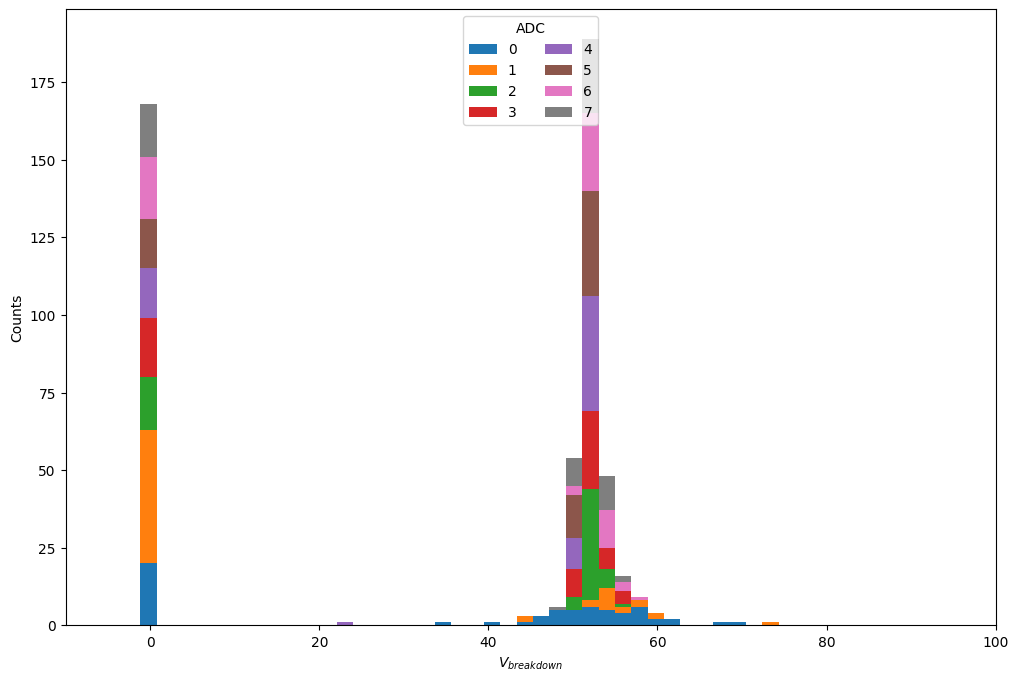

-1.0
-1.0
-1.0
-1.0
54.2
49.01
49.48
-1.0
47.93
46.66
51.14
58.03
51.09
50.29
51.93
57.22
-1.0
-1.0
-1.0
-1.0
-1.0
53.16
122.7
58.63
48.83
48.54
58.03
52.85
49.7
45.81
69.91
59.67
-1.0
-1.0
-1.0
-1.0
61.57
54.17
51.27
56.21
52.6
53.69
57.94
45.2
35.25
61.29
51.11
57.49
-1.0
-1.0
-1.0
-1.0
46.15
-1.0
56.22
68.21
-1.0
53.75
55.17
59.88
50.6
48.8
56.51
40.62
-1.0
-1.0
-1.0
-1.0
-1038.5
45.05
53.85
55.05
-241.25
54.96
53.47
54.2
59.76
73.28
44.48
56.59
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
59.39
52.64
-1.0
52.54
-1.0
-1.0
-1.0
-1.0
53.08
57.72
-1.0
54.44
-1.0
-1.0
-1.0
-1.0
-1.0
58.36
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
105.16
-1.0
54.42
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
-1.0
51.85
51.24
49.85
51.17
51.73
51.43
53.48
51.41
50.88
51.84
51.46
51.55
-1.0
-1.0
-1.0
-1.0
51.57
51.81
51.11
51.43
51.11
51.32
51.82
51.65
51.1
51.61
51.42
51.17
-1.0
-1.0
-1.0
-1.0
51.43
51.59
51.8
51.23
51.75
51.74
51.09
51.55
51.94
51.84
51.54
51.37
-1.0
-1.0
-1.0
-1.0
51.

In [6]:
# BD Voltages
fit_res[fit_res==0] = 200
V = -1*fit_res[...,0]/fit_res[...,1]
#V = V[:,sipm_channels]
label = np.arange(0,8)
fig = plt.gcf()
fig.patch.set_facecolor('white')

data_nonneg = np.array(V.T)
data_nonneg = data_nonneg[data_nonneg >= 0]

plt.figure(figsize=(12,8))
plt.hist(V.T, bins=600, stacked=True, label=label) # includes failed fits/dead channels at x=-1
#plt.hist(data_nonneg, bins=60, stacked=True, label=label) # does not include failed fits/dead channels
plt.xlim(-10,100)
plt.xlabel("$V_{breakdown}$")
plt.ylabel("Counts")
plt.legend(title='ADC',loc='upper center',ncol=2)
plt.show()
text = '\n'.join((map(str, np.round(V.flatten(),2))))
print(text)

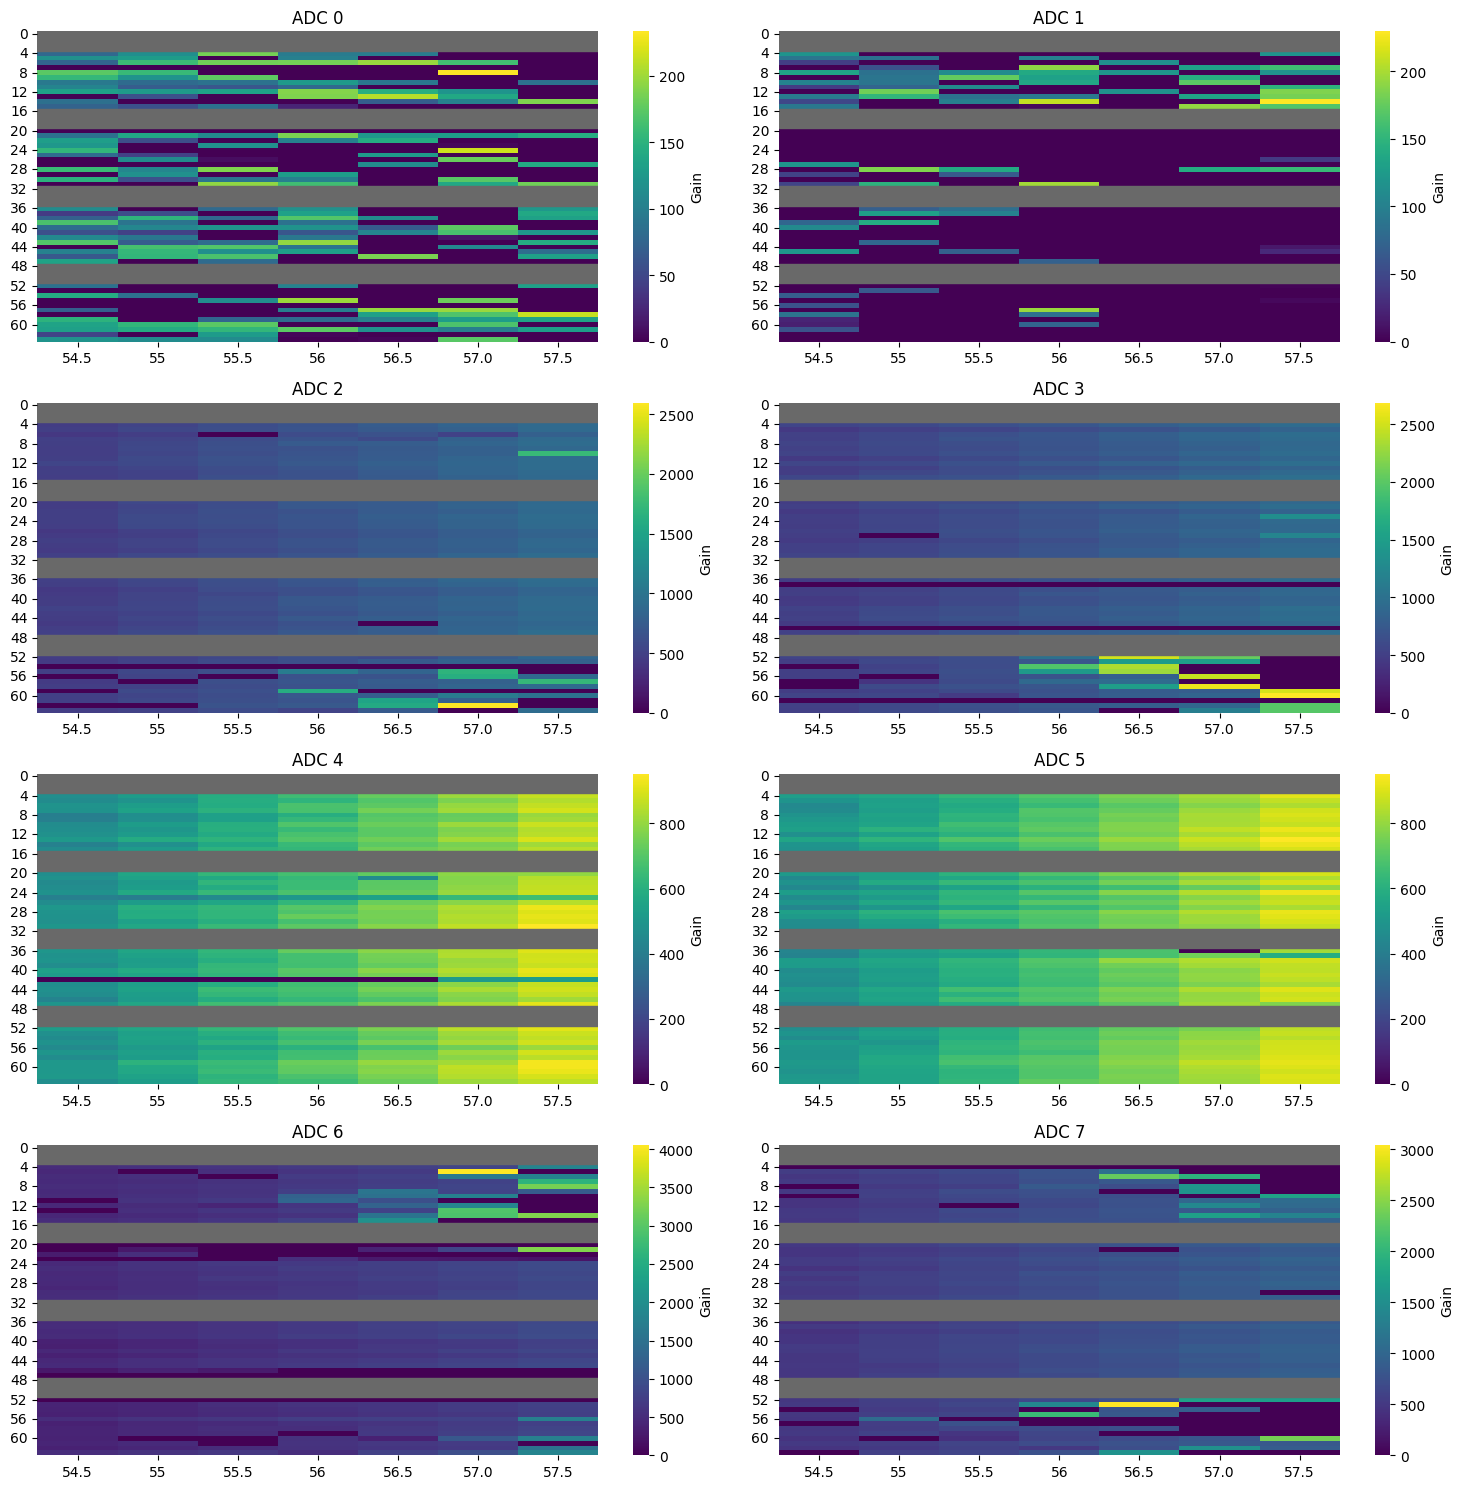

/tmp/ipykernel_2273144/733716251.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((0,ch),width=gains.shape[0],edgecolor='black', lw=1, height=1,color='dimgrey'))
/tmp/ipykernel_2273144/733716251.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((0,ch),width=gains.shape[0],edgecolor='black', lw=1, height=1,color='dimgrey'))
/tmp/ipykernel_2273144/733716251.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((0,ch),width=gains.shape[0],edgecolor='black', lw=1, height=1,color='dimgrey'))
/tmp/ipykernel_2273144/733716251.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((0,ch),width=gains.shape[0],edgecolor='black', lw=1, height=1,color='dimgrey'))
/tmp/ipykernel_2273144/733716251.py:36: 

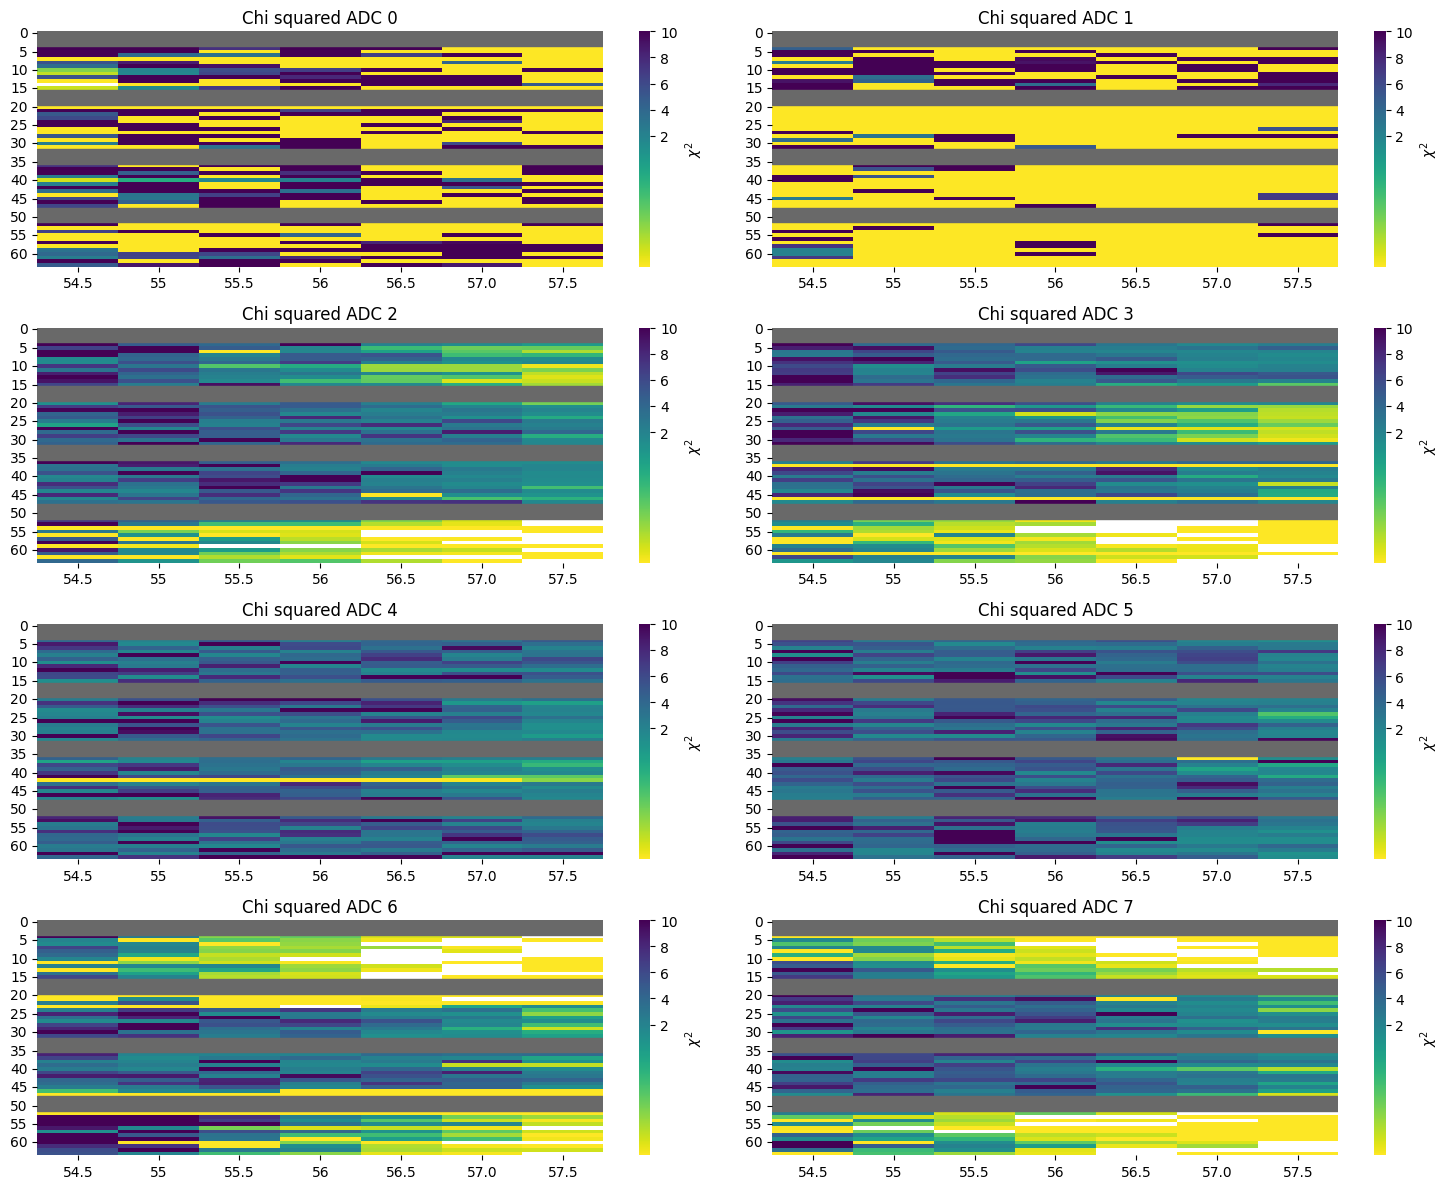

0


In [7]:
from matplotlib.patches import Rectangle
# Mask inactivate channels
mask = np.zeros(gains.shape[2])
mask[sipm_channels] = True

# Plot a heatmap per ADC
fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(15,15))
axs = axs.flatten()
for adc in range(gains.shape[1]):
    gains_per_adc = gains[:,adc,:,0]
    ax = axs[adc]
    sns.heatmap(gains_per_adc.T, ax=ax, cmap='viridis',xticklabels=voltages[:gains.shape[0]], cbar_kws={'label': 'Gain'})
    for ch in range(gains.shape[2]):
        if mask[ch] == False:
            ax.add_patch(Rectangle((0,ch),width=gains.shape[0], height=1,color='dimgrey'))
    ax.set_title("ADC {}".format(adc))

fig.tight_layout()
plt.show()



fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(15,12))
axs = axs.flatten()
vmin = 1e-6
vmax = 10
norm = TwoSlopeNorm(vmin=vmin, vcenter=1,vmax=vmax)
for adc in range(gains.shape[1]):
    stats_per_adc = gains[:,adc,:,1]#+1e-6 # To avoid log(0) in the log scale

    ax = axs[adc]
    sns.heatmap(stats_per_adc.T, ax=ax, cmap='viridis_r', norm=norm,xticklabels=voltages[:gains.shape[0]],cbar_kws={'label': r'$\chi^2$'})
    
    for ch in range(gains.shape[2]):
        if mask[ch] == False:
            ax.add_patch(Rectangle((0,ch),width=gains.shape[0],edgecolor='black', lw=1, height=1,color='dimgrey'))
    ax.set_title("Chi squared ADC {}".format(adc))

fig.tight_layout()
plt.show()

print(np.sum(gains[:,:,:,1]==1))

In [8]:
# Heatmap for all sipms together

heatmap_data = np.transpose(gains_v2[...,0], (1,2,0)).reshape(8*64,gains_v2.shape[0])
sns.heatmap(heatmap_data, cmap='viridis', cbar=True, xticklabels=voltages_v2[:gains_v2.shape[0]])
plt.xlabel('$V_{bias}$')
plt.ylabel("Channel")
labels = np.arange(0,64)*8
plt.yticks(labels)
plt.show()
print(labels)

NameError: name 'gains_v2' is not defined

In [ ]:
# James's plotting code
def plot_metric_div(
    metric,
    channel_status=None,
    log_scale=False,
    exclude_bad=True,
    mask_inactive=True,
    title='Metric',
    center=None,
    cmap='bwr'
):

    # Set up figure
    fig, ax = plt.subplots(figsize=(20, 4))
    # Mask bad channels if requested
    if channel_status is not None and exclude_bad:
        metric = np.ma.masked_where(channel_status != 0, metric)
    # If not excluding, make inactive (-1) NaN so it uses "bad" color; keep bad>0 for overlay
    if channel_status is not None and mask_inactive:
        inactive_idx = np.where(channel_status == -1)
        metric[inactive_idx] = np.nan
    # Colormap / norm
    if cmap == 'rwb':
        # reverse blue-white-red
        cmap = plt.cm.get_cmap('bwr').copy()
        cmap = cmap.reversed()
    cmap = plt.cm.get_cmap(cmap).copy()
    cmap.set_bad('black')  # masked/NaN shown as black for divergent
    # centre of divergence (white)
    if center is None:
        print ("Center not specified, using 0.0")
        center = 0.0
    # Determine a symmetric span about `center` that covers data *and* (if set) the window edges
    data_min = np.nanmin(metric)
    data_max = np.nanmax(metric)
    candidates = [max(0.0, center - data_min), max(0.0, data_max - center)]
    half_span = max(candidates) if candidates else 1.0
    if not np.isfinite(half_span) or half_span <= 0:
        half_span = 1.0
    # log scale with SymLogNorm
    if log_scale:
        # Shift so that white (0 after shift) is at 'center'
        shifted = metric - center
        # Choose a linear threshold for SymLog (smallest nonzero |shifted| with a floor)
        nz = np.abs(shifted)
        nz = nz[nz > 0]
        linthresh = max(np.nanmin(nz) if nz.size else 0.0, half_span * 1e-3)
        norm = colors.SymLogNorm(
            linthresh=linthresh,
            vmin=-half_span,
            vmax=+half_span,
            base=10.0
        )

        im = ax.imshow(shifted, cmap=cmap, norm=norm, aspect='auto')

        # Colorbar shows original (unshifted) values
        cbar = plt.colorbar(im, ax=ax, label=title)
        cbar.formatter = ticker.FuncFormatter(lambda val, pos: f"{val + center:g}")
        cbar.update_ticks()
    else:
        # Linear divergent symmetric scaling
        norm = colors.TwoSlopeNorm(vmin=center - half_span, vcenter=center, vmax=center + half_span)
        im = ax.imshow(metric, cmap=cmap, norm=norm, aspect='auto')
        plt.colorbar(im, ax=ax, label=title)

    # Overlay bad channels if not excluded
    if channel_status is not None and not exclude_bad:
        color = 'k'
        bad_idx = np.where(channel_status > 0)
        for y, x in zip(*bad_idx):
            ax.scatter(x, y, s=100, c=color, marker='o', edgecolors='none', zorder=10)

    # Axes styling
    ax.set_xticks(np.arange(0, 64, 1) - 0.5)
    ax.set_yticks(np.arange(0, 8, 1) - 0.5)
    ax.set_xticklabels(np.arange(0, 64, 1))
    ax.set_yticklabels(np.arange(0, 8, 1))
    plt.xlabel('Channel')
    plt.ylabel('ADC')
    plt.grid(which='both', linewidth=0.5, alpha=0.5, color='white')
    plt.tight_layout()
    plt.title(title)
    plt.show()

In [ ]:
# Now fit

# First only for ADC7
data_adc7 = gains[:,7,...]
print(data_adc7[...,0].shape)
for chan in range(data_adc7.shape[1]):
    plt.scatter(voltages, data_adc7[:,chan,0])
plt.show()

# I want to include only non-zero values in my fit.
# Here I filter out zeros for each row(=voltage)

cleaned = []
for row in data_adc7[...,0]:
    values = row[row!=0]
    channels = np.arange(48)[row!=0] # Keep track of the channels
    cleaned.append((values, channels))

for idx, (values, channels) in enumerate(cleaned):
    plt.scatter(channels, values, label=voltages[idx])
plt.legend()
plt.show()

In [ ]:
# Actual fitting
fit_res_adc7 = []

plt.figure()

for ch in range(0,data_adc7.shape[1]):
    gains_per_chan = data_adc7[:,ch,0]
    mask = (gains_per_chan !=0)
    gains_per_chan_cleaned = gains_per_chan[mask]
    voltages_cleaned = voltages[mask]
    
    cut_1 = (len(gains_per_chan_cleaned) > 2)  # Let's only attempt a fit for 3+ datapoints
    indices_cleaned = np.where(mask)[0]
    cut_2 = (np.any(np.diff(indices_cleaned)) == 1) # Checks if the non-zero array has data for two consecutive voltages

    try:
        cut_3 = ((gains_per_chan_cleaned[-1] - gains_per_chan_cleaned[0]) > 0) # If the final value is smaller than the first, something must have gone wrong
    except:
        print("No fit for ch", ch)
        pass
    if cut_1 * cut_2 * cut_3 == 1:

        coeffs = np.polyfit(voltages_cleaned, gains_per_chan_cleaned, deg=1)
        fit_res_adc7.append(coeffs)
        f_lin = np.poly1d(coeffs)
        x_fit = np.linspace(min(voltages_cleaned), max(voltages_cleaned), 100)
        y_fit = f_lin(x_fit)
    #    plt.scatter(voltages_cleaned, gains_per_chan_cleaned)
        plt.plot(x_fit, y_fit, label=ch)
        
    else:
        print("No fit for channel {}".format(ch))
del coeffs
plt.legend()
plt.show()
fit_res = np.array(fit_res)
V_BD_adc7 = -fit_res_adc7[:,1]/fit_res_adc7[:,0]

In [ ]:
# Now for all ADC's
fit_res = np.zeros((8,48,2))

for adc in range(0, gains.shape[1]):

    for ch in range(0,data_adc7.shape[1]):

        gains_per_chan = gains[:,adc,ch,0]
        mask = (gains_per_chan !=0)
        gains_per_chan_cleaned = gains_per_chan[mask] # Take out zeros (per channel)
        voltages_cleaned = voltages[mask]
    
        cut_1 = (len(gains_per_chan_cleaned) > 2)  # Let's only attempt a fit for 3+ datapoints
        indices_cleaned = np.where(mask)[0]
        cut_2 = (np.any(np.diff(indices_cleaned)) == 1) # Checks if the non-zero array has data for two consecutive voltages

        try:
            cut_3 = ((gains_per_chan_cleaned[-1] - gains_per_chan_cleaned[0]) > 0) # If the final value is smaller than the first, something must have gone wrong
        except:
            print(f"No fit for ADC {adc} ch {ch}")
            pass
        if cut_1 * cut_2 * cut_3 == 1:

            coeffs = np.polyfit(voltages_cleaned, gains_per_chan_cleaned, deg=1)
            fit_res[adc, ch, :] = coeffs

            # For plotting
            if adc == 0: # I want to see what happens at ADC0 rn

                f_lin = np.poly1d(coeffs)
                x_fit = np.linspace(min(voltages_cleaned), max(voltages_cleaned), 100) 
                y_fit = f_lin(x_fit) 
                plt.plot(x_fit, y_fit) # Horrible

        else:
            print(f"No fit for adc {adc} channel {ch}")

NameError: name 'data_adc7' is not defined

In [ ]:
with np.errstate(divide='ignore', invalid='ignore'): # Because there WILL be zeros...
    V_BD = -fit_res[...,1]/fit_res[...,0]

In [ ]:
# How many presumably correct values do we have?
values_1 = V_BD[~np.isnan(V_BD)]
values_2 = values_1[(values_1>40) & (values_1<45)] # From the datasheet I expect the values to be at least in this range.

#print(values_2)
print(f"Values for {len(values_2)} out of 384" )
print("Mean V_BD is ", np.mean(values_2))

In [ ]:
print((np.sum(gains[:,:,:,1]) > 0.5 & np.sum(gains[;,:,:,1] < 1.5))

In [ ]:
teller = 0
for adc in range(0,8):
    for ch in range(0,48):
        #print(gains[:,adc,ch,1])
        for file in range(0,gains.shape[0]):
            if gains[file,adc,ch,1] > 0.5:
                if gains[file,adc,ch,1] < 1.5:
                    teller += 1
                    print(gains[file,adc,ch,1])

In [ ]:
teller

In [ ]:
import numpy as np
waveform_data = []
for files in range(0,3):
    waveform_data_temp = np.zeros((6000,8,64,200))
    waveform_data.append(waveform_data_temp)
waveform_data = np.concatenate(waveform_data)
waveform_data.shape

In [ ]:
x = np.concatenate(waveform_data)

In [ ]:
inputs = ['sfsd',
          'fsdfs']
for i in inputs:
    print(i)